# Polyp Segmentation — Model Results

**Prepared by:** Teerawat Saenum

This executable report compares YOLO26m-seg and YOLO26s-seg on the same **1,390-image balanced test set**. Its saved tables and figures appear immediately on GitHub. Rerunning it uses only the CSV and PNG files in this repository; weights and the image archive are not needed.

See the [README](README.md) for experiment settings and the [dataset repository](https://github.com/YABYABuwu/Multi-Source-Polyp-Segmentation-Dataset) for data provenance.

In [1]:
from pathlib import Path
from html import escape
from IPython.display import HTML, Image, display
from scripts.build_summary import read_csv, summarize

ROOT = Path.cwd()
if not (ROOT / "runs" / "yolo26m" / "full_test_per_image_metrics.csv").is_file():
    raise FileNotFoundError("Start Jupyter from the model-results repository directory")

def table(headers, rows):
    head = "".join(f"<th>{escape(str(x))}</th>" for x in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(x))}</td>" for x in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

def load_subset(filename):
    rows = {model: read_csv(ROOT / "runs" / model / filename) for model in ("yolo26m", "yolo26s")}
    first = {r["id"]: r["gt_present"] for r in rows["yolo26m"]}
    assert {r["id"]: r["gt_present"] for r in rows["yolo26s"]} == first
    return {model: summarize(items) for model, items in rows.items()}

full = load_subset("full_test_per_image_metrics.csv")
wli = load_subset("primary_wli_balanced_test.csv")
print("Matched test IDs and ground-truth labels verified.")

Matched test IDs and ground-truth labels verified.


## Full balanced test: 695 positive + 695 negative

TP/FN/TN/FP measure image-level polyp presence. Dice and IoU are means over positive images only.

Model,TP,FN,TN,FP,Sensitivity,Specificity,Dice+,IoU+
YOLO26M,666,29,671,24,95.8%,96.5%,0.893,0.847
YOLO26S,678,17,646,49,97.6%,92.9%,0.901,0.851


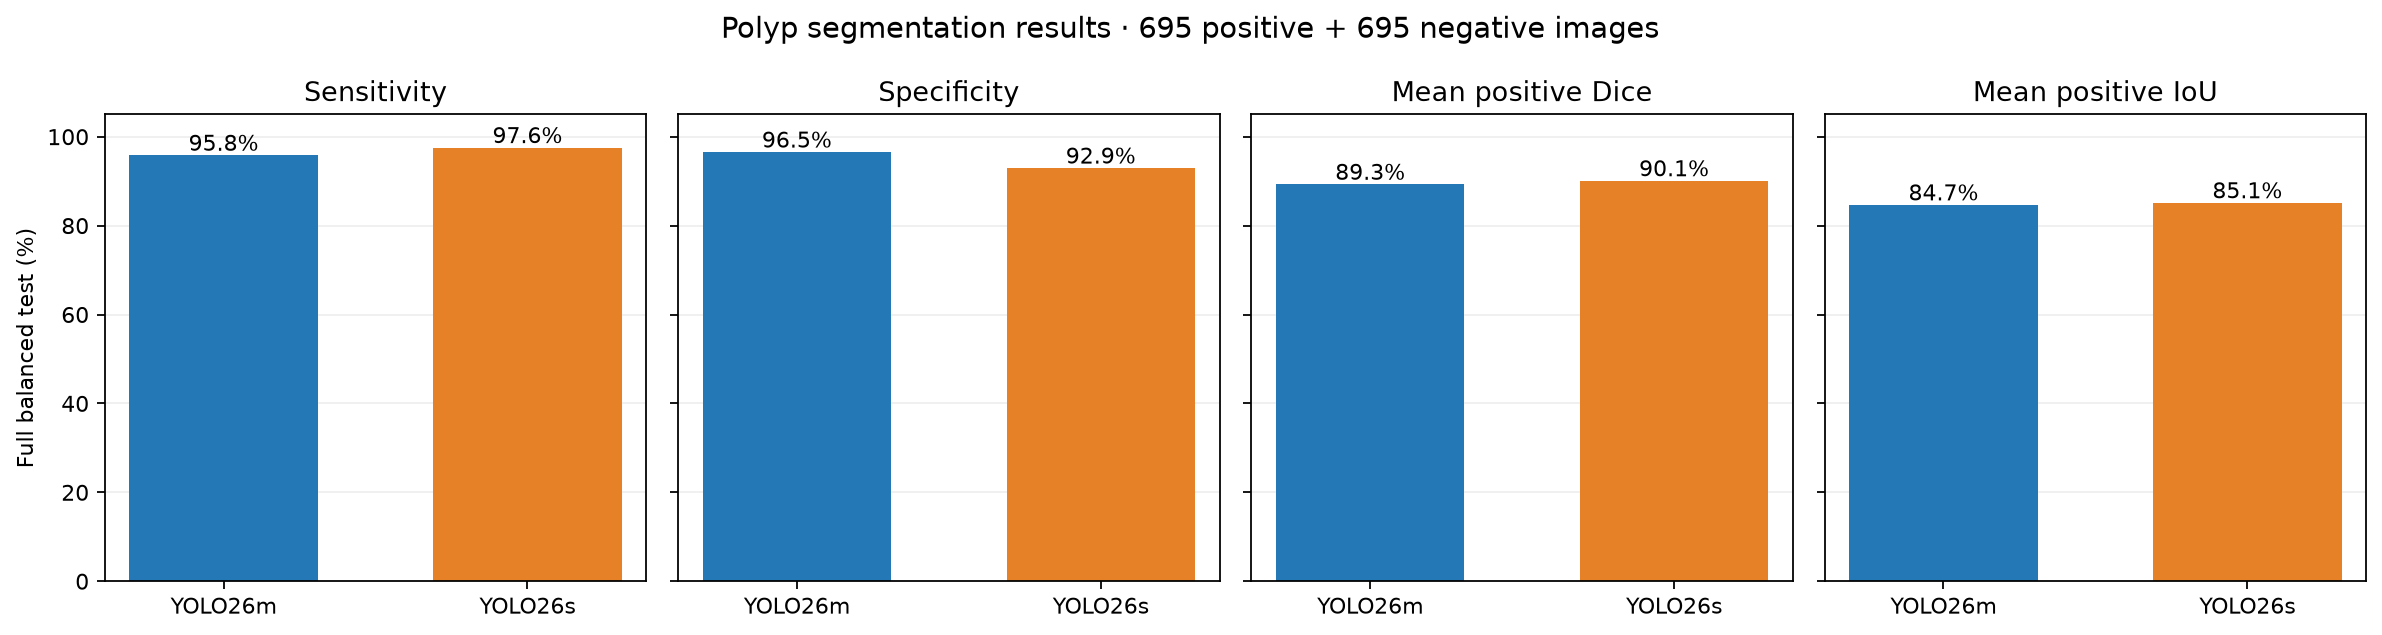

In [2]:
def metric_rows(data):
    return [(model.upper(), m["tp"], m["fn"], m["tn"], m["fp"],
             f'{m["sensitivity"]:.1%}', f'{m["specificity"]:.1%}',
             f'{m["mean_positive_dice"]:.3f}', f'{m["mean_positive_iou"]:.3f}')
            for model, m in data.items()]

assert full["yolo26m"]["images"] == full["yolo26s"]["images"] == 1390
table(("Model", "TP", "FN", "TN", "FP", "Sensitivity", "Specificity", "Dice+", "IoU+"), metric_rows(full))
display(Image(filename=str(ROOT / "figures" / "model_comparison.png")))

## WLI/standard subset: 437 positive + 437 negative

These 874 images are part of the full test above, not a second independent test set.

In [3]:
assert wli["yolo26m"]["images"] == wli["yolo26s"]["images"] == 874
table(("Model", "TP", "FN", "TN", "FP", "Sensitivity", "Specificity", "Dice+", "IoU+"), metric_rows(wli))

Model,TP,FN,TN,FP,Sensitivity,Specificity,Dice+,IoU+
YOLO26M,420,17,413,24,96.1%,94.5%,0.897,0.850
YOLO26S,425,12,398,39,97.3%,91.1%,0.899,0.849


## Image-level confusion matrices

YOLO26M
YOLO26S


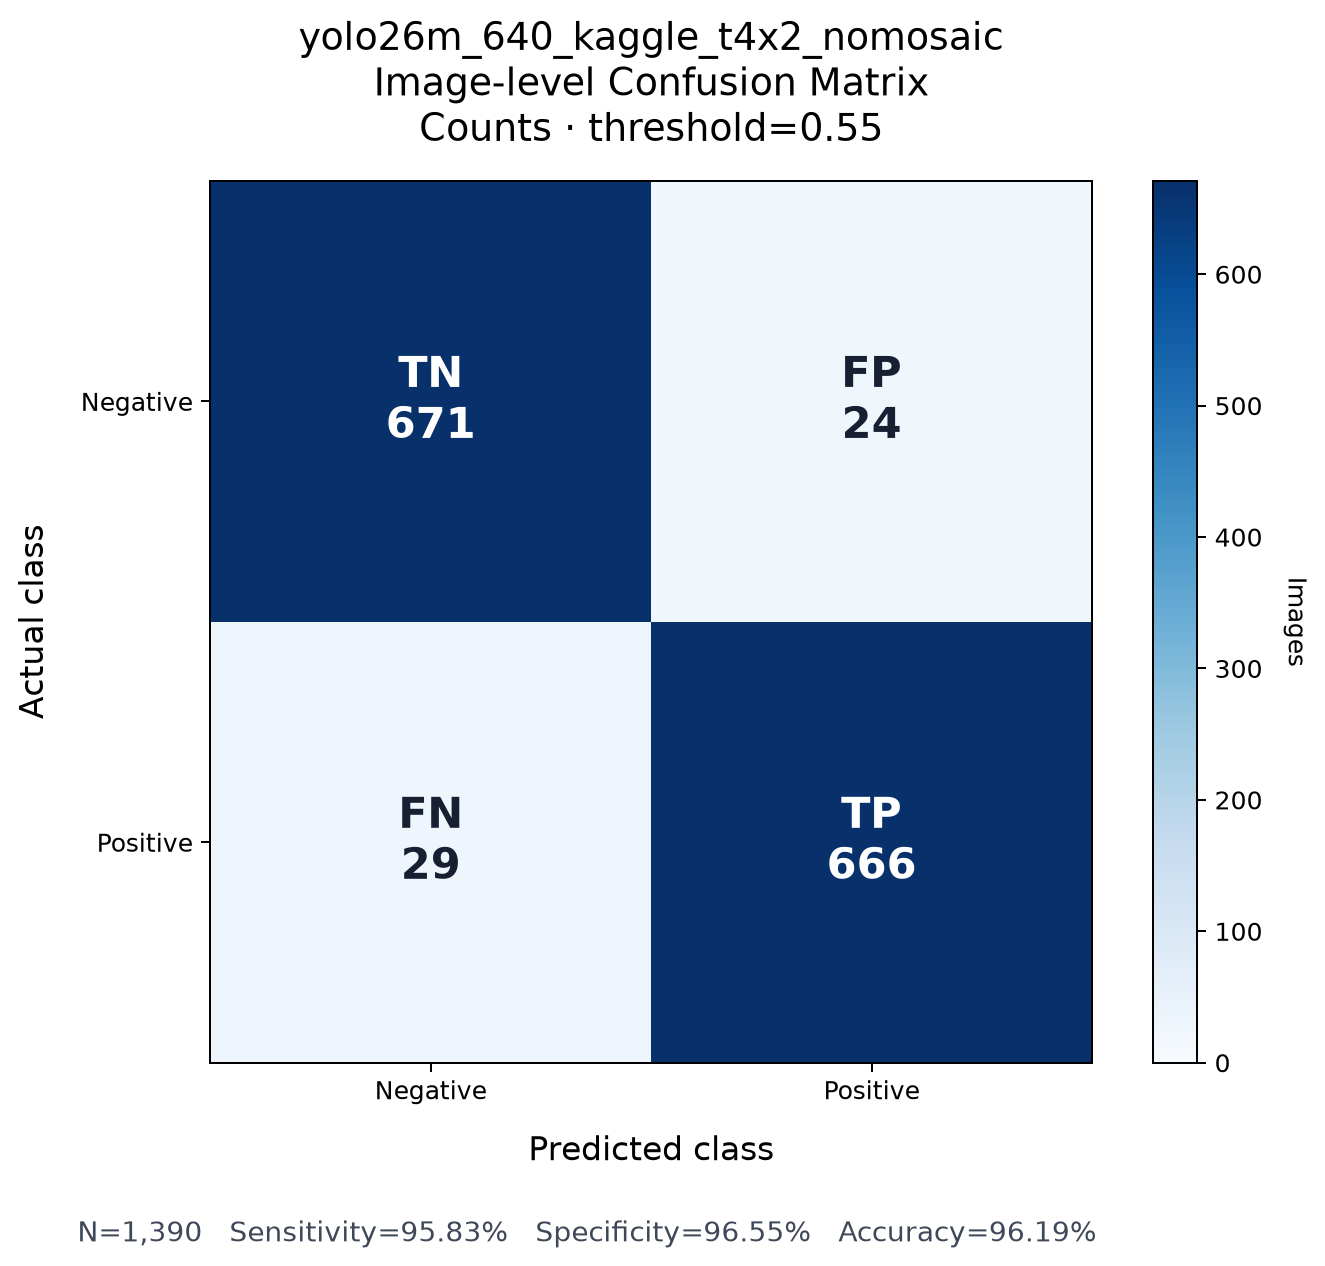

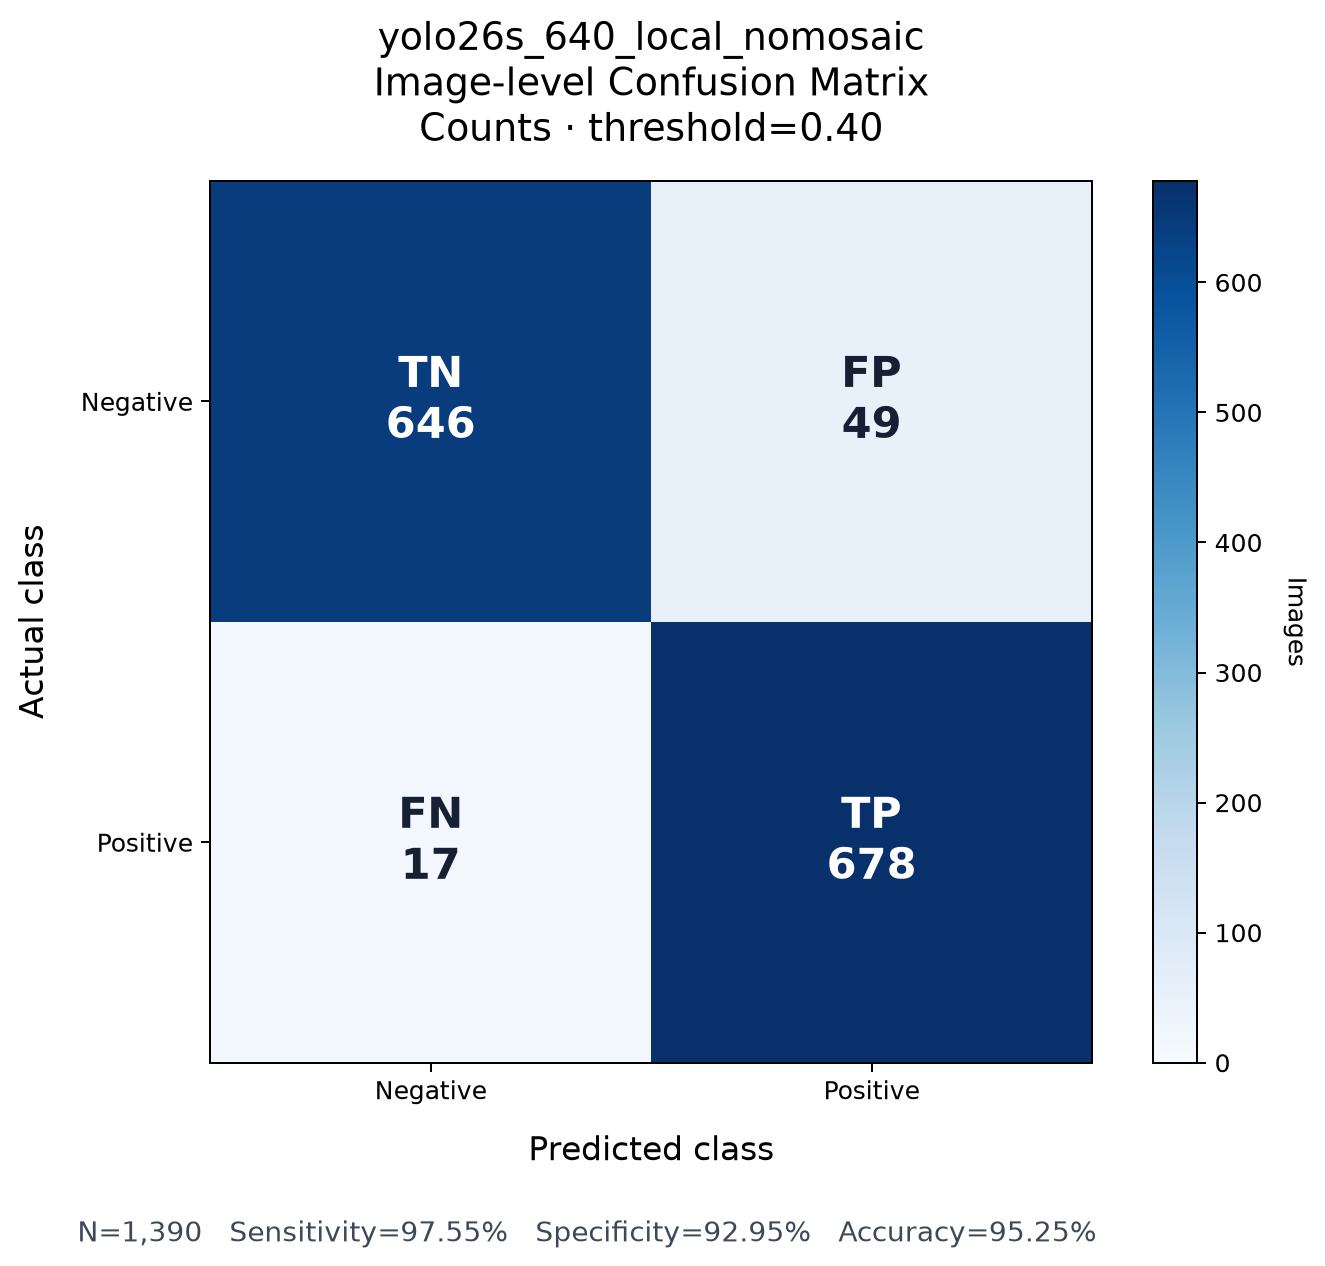

In [4]:
for model in ("yolo26m", "yolo26s"):
    print(model.upper())
    display(Image(filename=str(ROOT / "runs" / model / "image_level_confusion_matrix.png")))

## Qualitative error cases

These saved examples illustrate failures; the full per-image CSVs support the numerical evaluation.

YOLO26M
YOLO26S


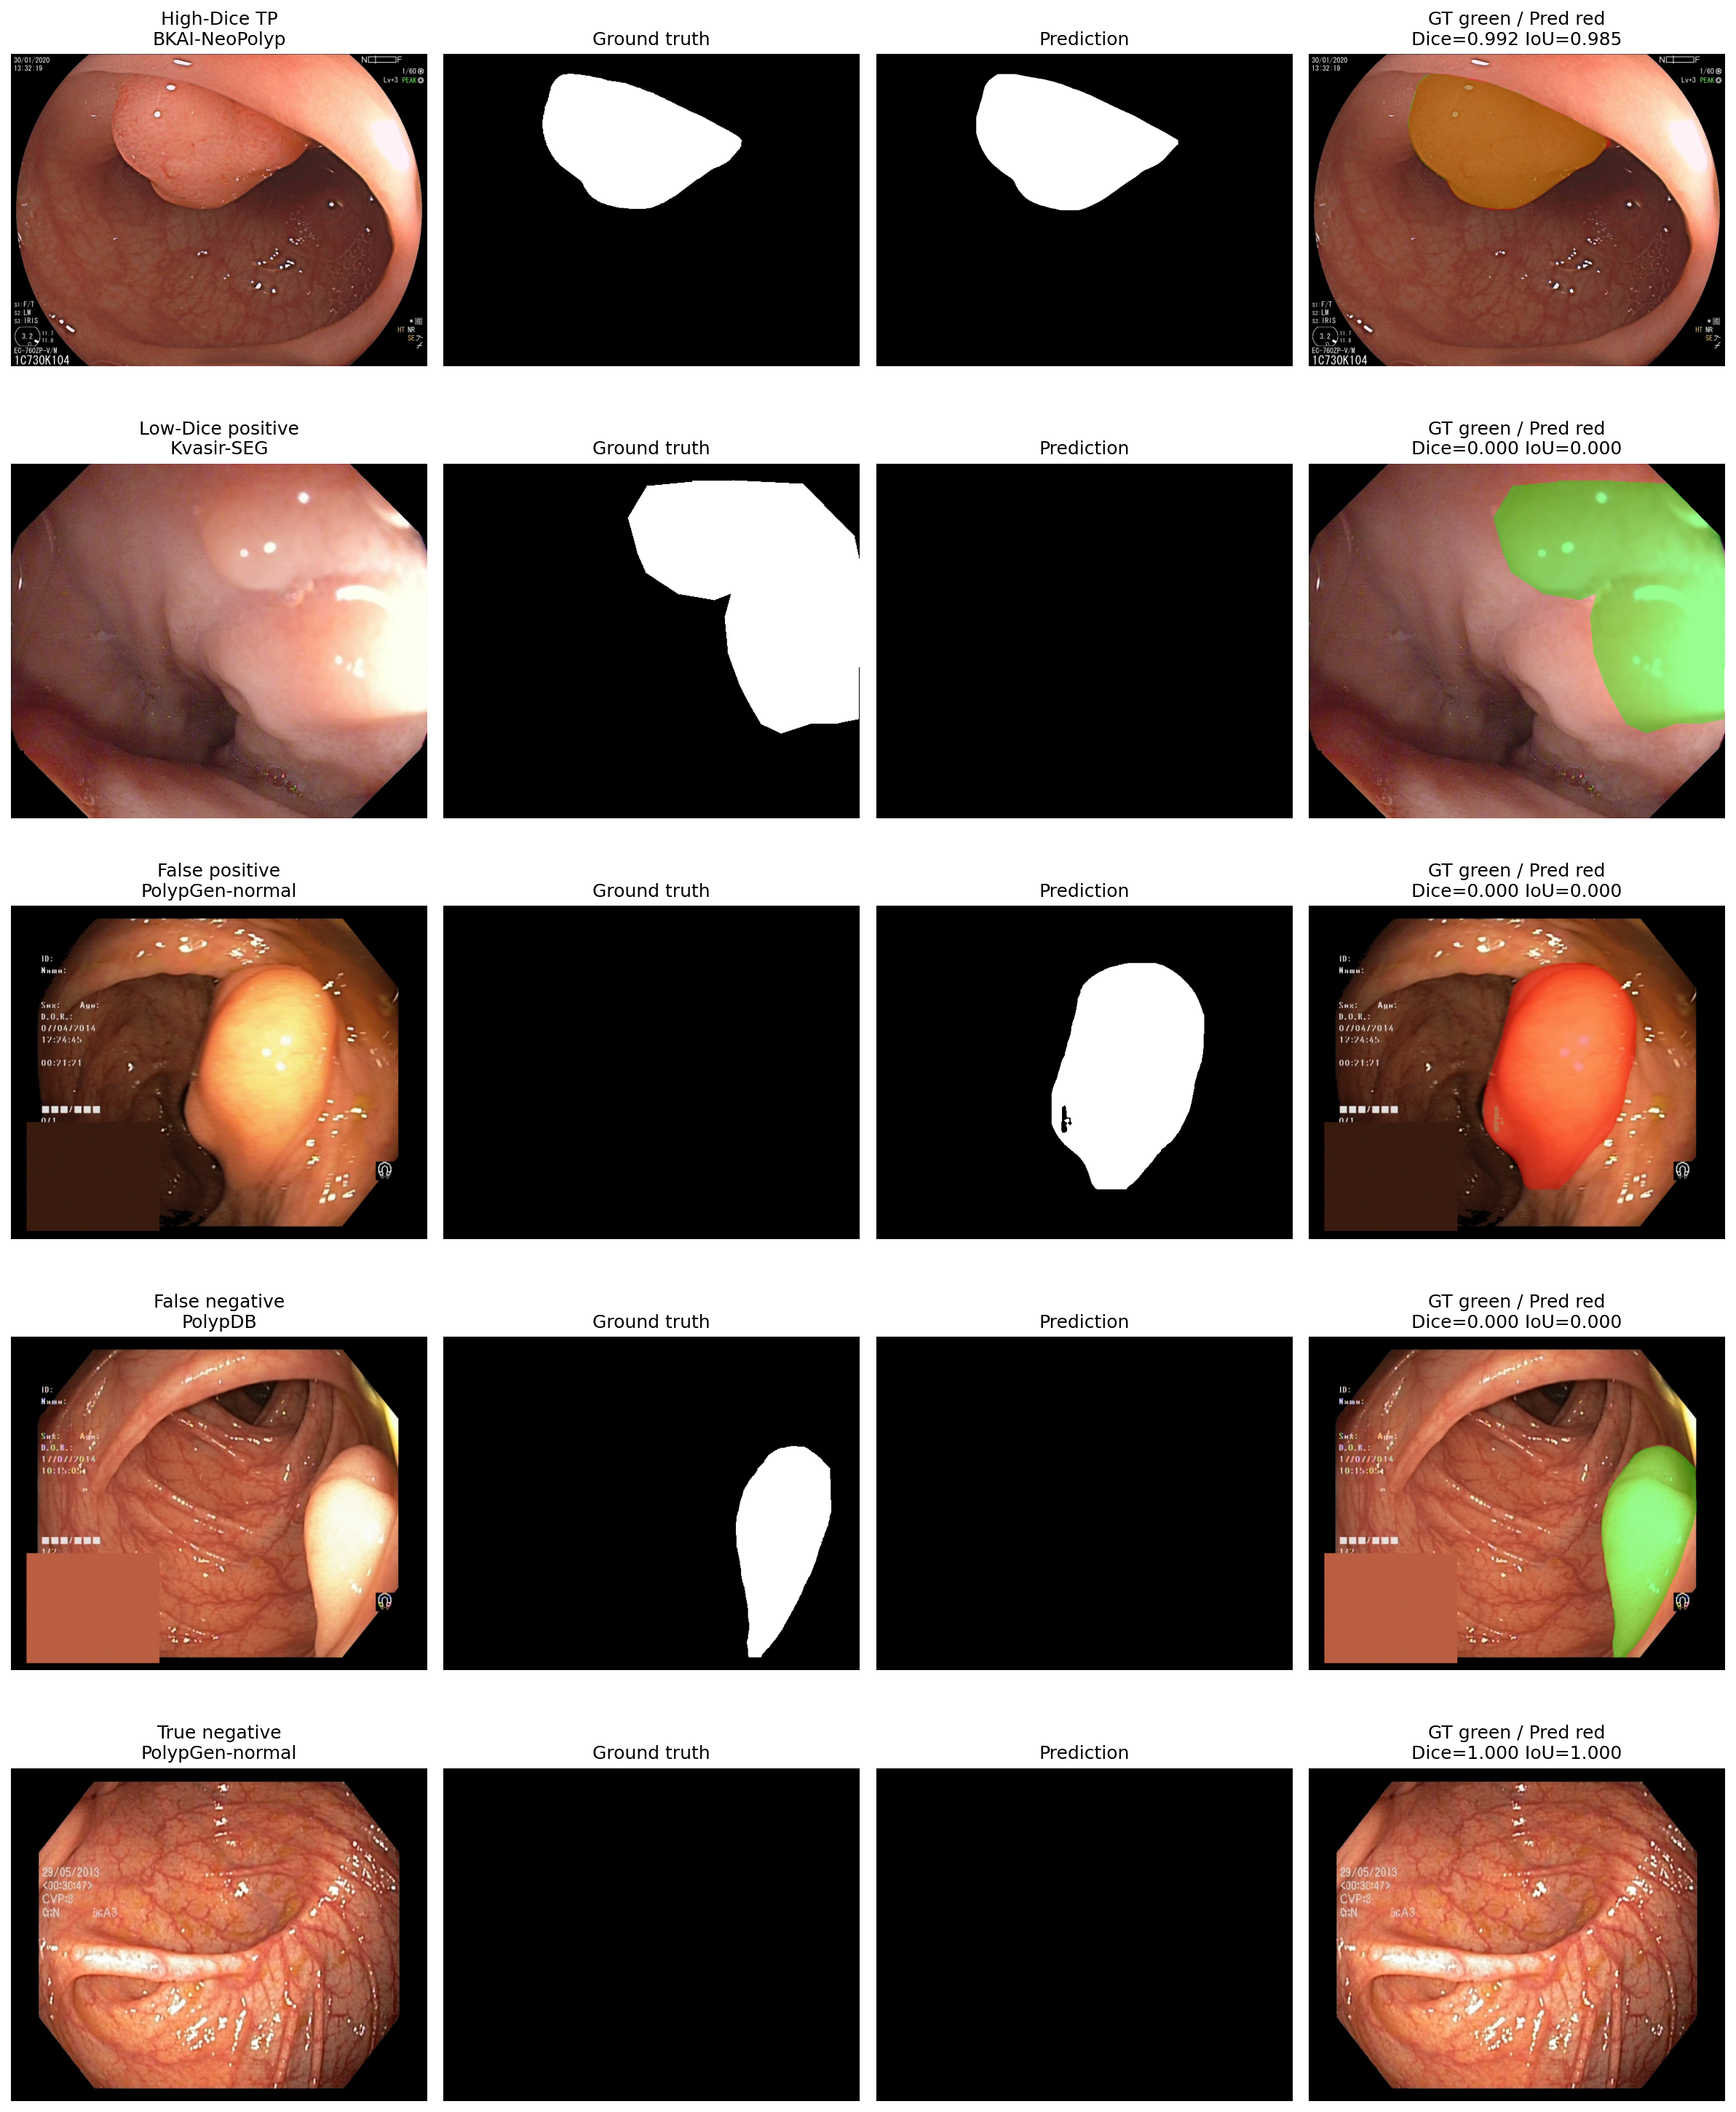

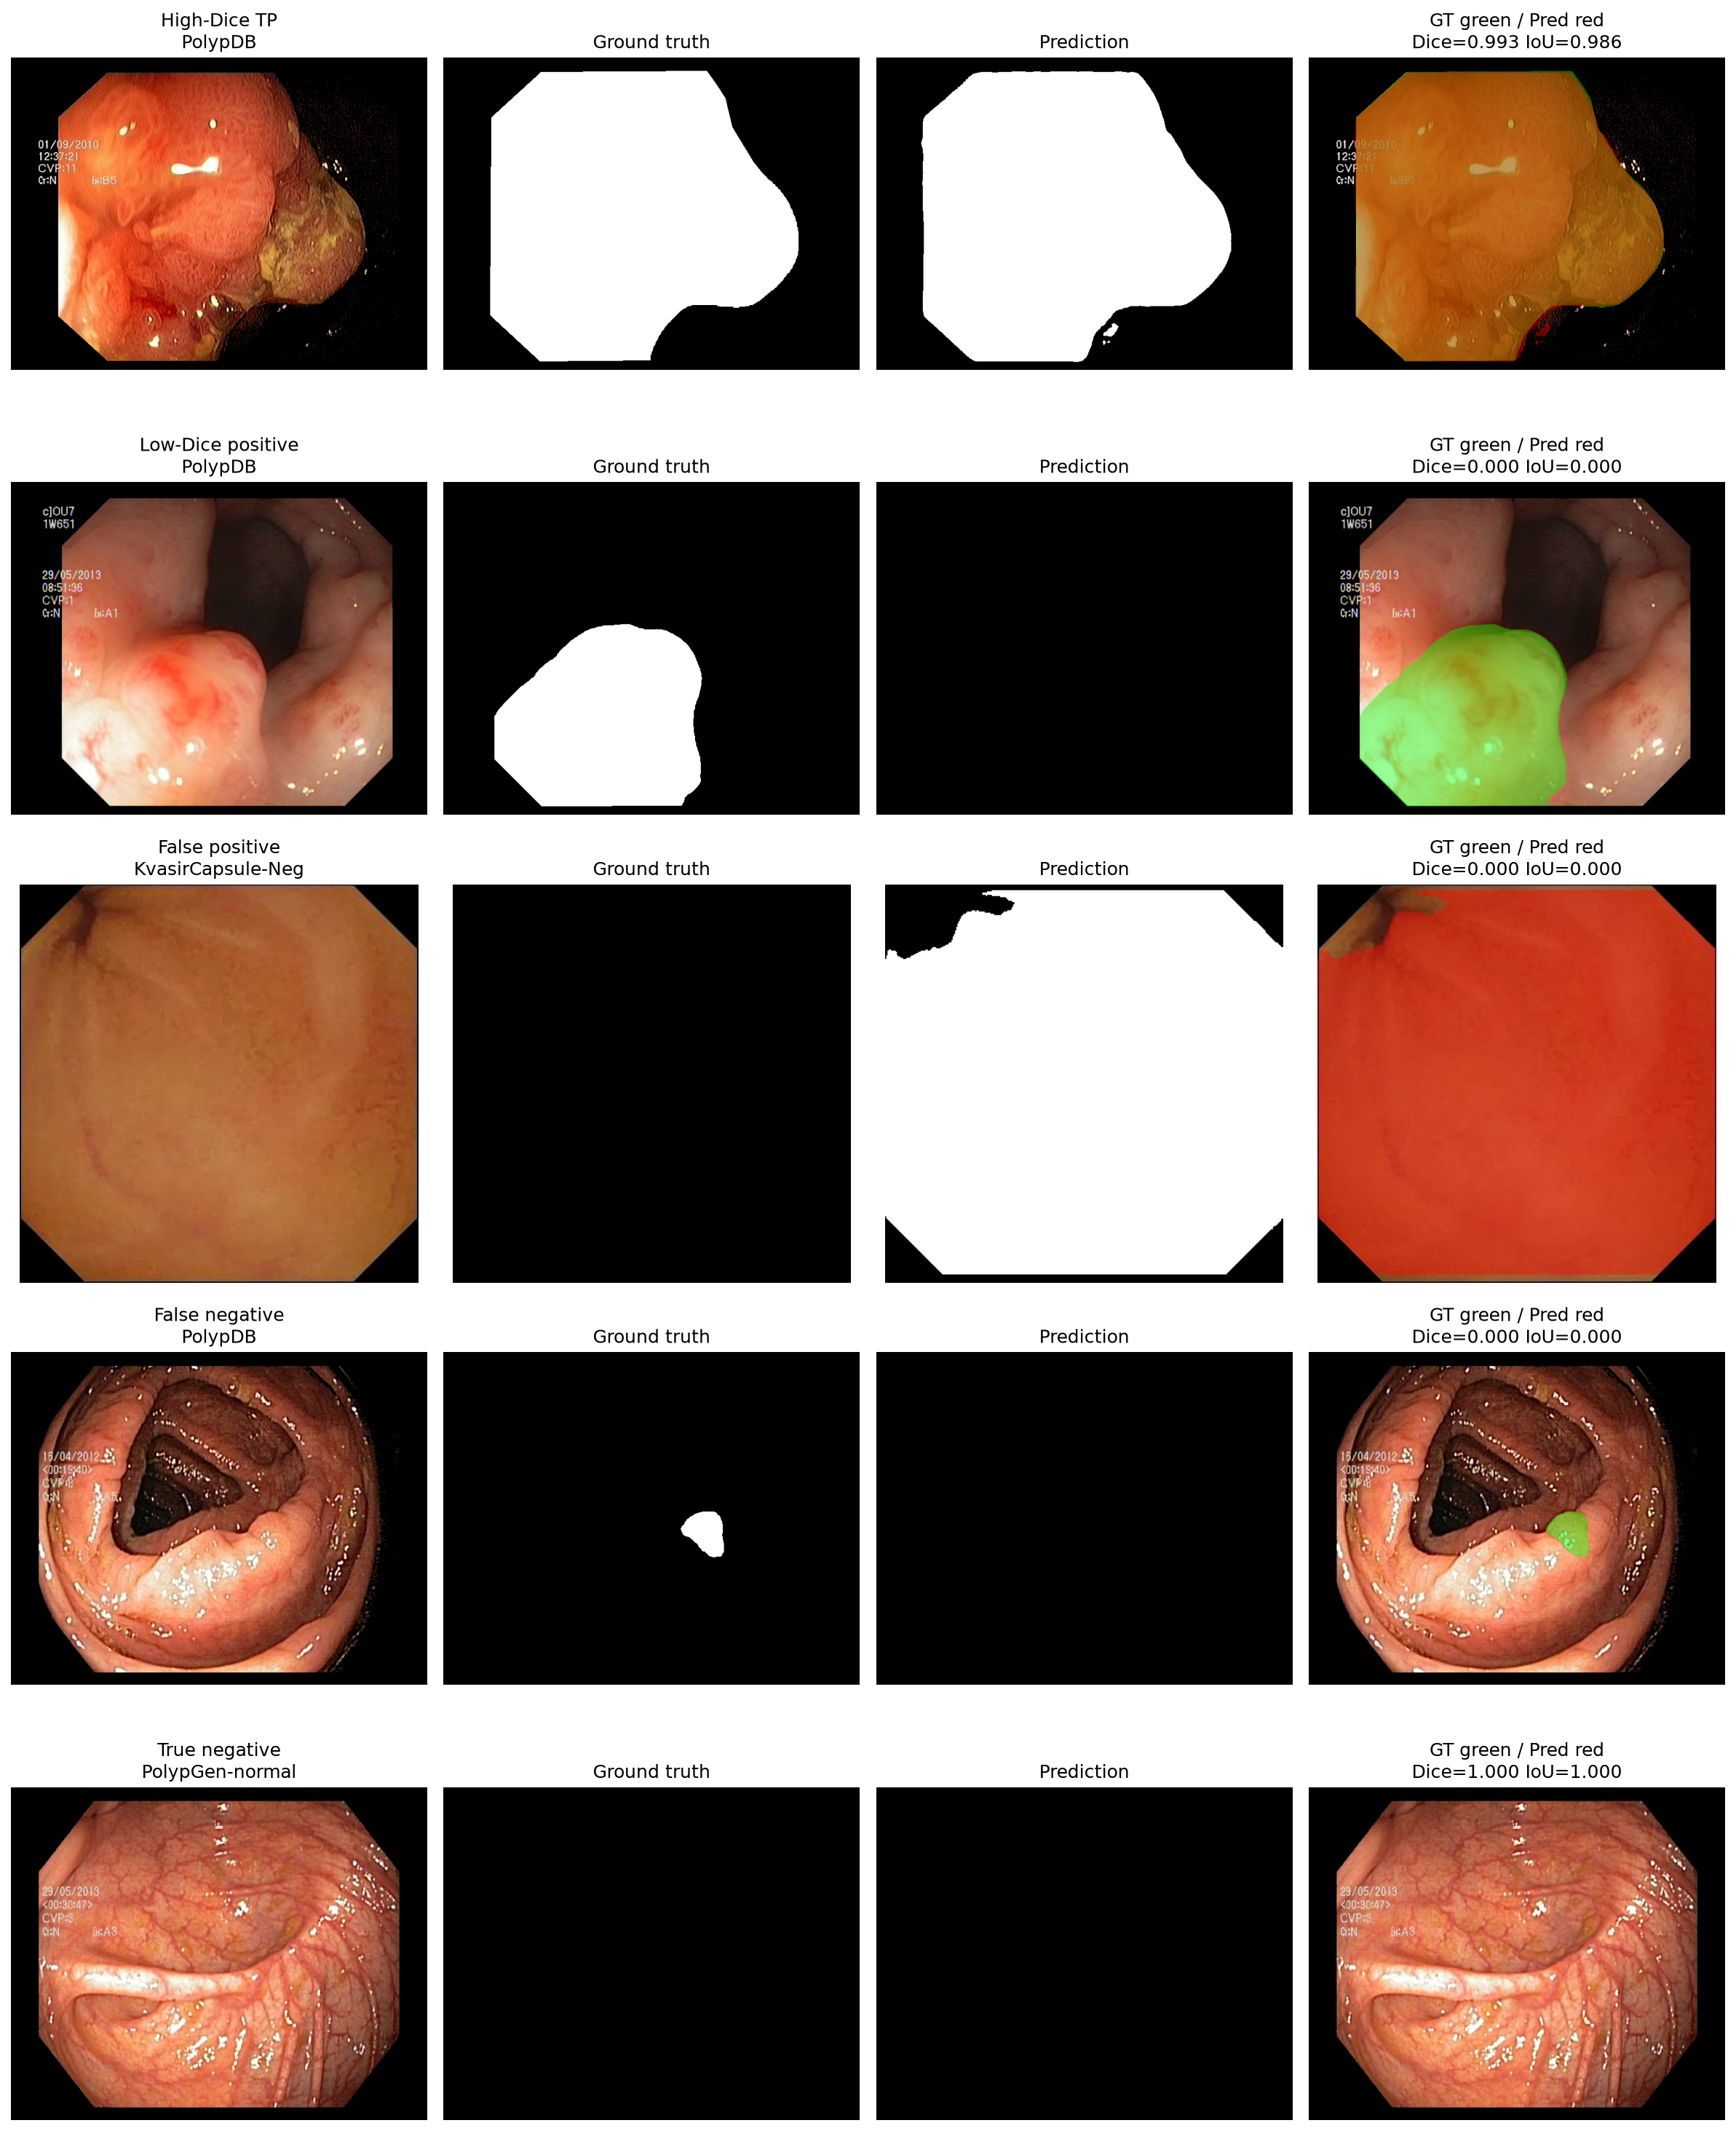

In [5]:
for model in ("yolo26m", "yolo26s"):
    print(model.upper())
    display(Image(filename=str(ROOT / "runs" / model / "qualitative_error_cases.png")))

## Interpretation and limits

YOLO26s detected more positive images and had slightly higher mean positive Dice; YOLO26m produced fewer false positives. Hardware and batch sizes differed between runs. Confidence thresholds were selected on validation data (0.55 for YOLO26m, 0.40 for YOLO26s). These saved results do not establish patient-independent clinical performance. Model files: [YOLO26m Google Drive folder](https://drive.google.com/drive/folders/1LsY1JsxvAjfsGRvKxvEF3HoyIkbT7rjx?usp=sharing) and [YOLO26s Google Drive folder](https://drive.google.com/drive/folders/1j2ZCzcnGH4RrQUeMKQX8iLg98uFQFsWP?usp=sharing). See the [README](README.md) for the full experiment description.